# Convertible Bonds: Pricing the Bond, the Option and the Credit Risk

**Goal.** A convertible bond pays coupons like a bond and can be exchanged for shares.
Investors (and convertible funds such as those sold by asset managers to private banks and
wealth advisers) like it for its **asymmetry**: it follows the stock up and is cushioned
by the bond on the way down. This project prices it with the **Tsiveriotis-Fernandes**
binomial tree, which separates the equity part from the credit-risky cash part.

| Term | Value |
|---|---|
| Face value | 100 |
| Coupon | 2% annual |
| Maturity | 5 years |
| Conversion ratio | 1 share per bond (conversion price 100) |
| Stock price today | 80 (the option is out of the money) |
| Issuer credit spread | 200 bp over a 3% risk-free rate |

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("convertible.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/07-convertible-bond")

from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from convertible import Convertible, Market, price, bond_floor, implied_credit_spread

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"
cb, m = Convertible(), Market()
res = price(cb, m, full_output=True)
pd.Series(res).round(4).to_frame("Value")

,Value
price,105.4116
delta,0.5855
gamma,0.0071
parity,80.0000
bond_floor,86.5087
conversion_premium,0.3176
premium_over_floor,0.2185
equity_delta,0.4444


## 1. The tree: two parts, two discount rates

On each node the tree carries the total value $V$ and its **cash-only part** $B$:

$$B_t = e^{-(r+s)\Delta t}\,\mathbb{E}[B_{t+\Delta t}], \qquad
  V_t - B_t = e^{-r\Delta t}\,\mathbb{E}[V_{t+\Delta t} - B_{t+\Delta t}]$$

Cash flows that will be paid in cash carry the issuer's default risk, so they are
discounted at $r + s$; flows that end in shares are discounted at $r$. Then, at each node:
the holder converts if $\text{ratio} \times S > V$, the issuer calls if $V$ exceeds the
call price, and the holder puts if the put price exceeds $V$.

## 2. The convertible profile

The classic chart of the asset class: the convertible sits above both the **bond floor**
(its value as straight debt) and **parity** (its value in shares).

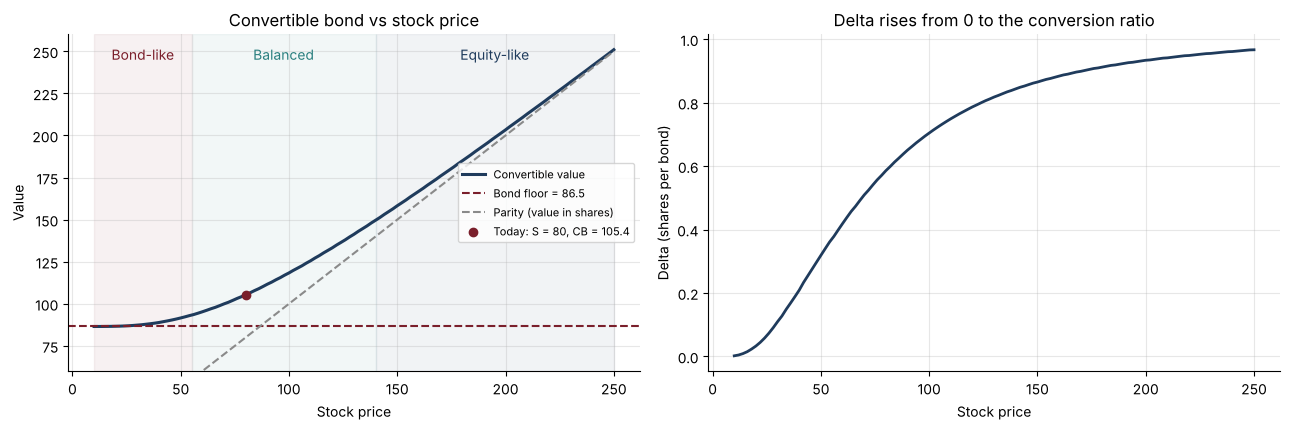

In [2]:
spots = np.linspace(10, 250, 121)
vals = [price(cb, replace(m, spot=s)) for s in spots]
V = np.array([v["price"] for v in vals]); D = np.array([v["delta"] for v in vals])
floor = bond_floor(cb, m)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
ax.plot(spots, V, color=NAVY, lw=2.2, label="Convertible value")
ax.axhline(floor, color=BORDEAUX, ls="--", label=f"Bond floor = {floor:.1f}")
ax.plot(spots, cb.conversion_ratio * spots, color=GREY, ls="--", label="Parity (value in shares)")
for lo, hi, name, c in [(10, 55, "Bond-like", BORDEAUX), (55, 140, "Balanced", TEAL), (140, 250, "Equity-like", NAVY)]:
    ax.axvspan(lo, hi, color=c, alpha=0.06); ax.text((lo + hi) / 2, 245, name, ha="center", color=c)
ax.scatter([m.spot], [res["price"]], color=BORDEAUX, zorder=4, label=f"Today: S = 80, CB = {res['price']:.1f}")
ax.set(xlabel="Stock price", ylabel="Value", title="Convertible bond vs stock price", ylim=(60, 260)); ax.legend(loc="center right", fontsize=8)
axes[1].plot(spots, D, color=NAVY, lw=2)
axes[1].set(xlabel="Stock price", ylabel="Delta (shares per bond)", title="Delta rises from 0 to the conversion ratio")
plt.tight_layout(); plt.savefig("images/cb_profile.png", dpi=150); plt.show()

**Reading the chart.** Far out of the money the convertible behaves like a bond (delta
near 0); deep in the money it behaves like the shares (delta near 1). In between, in the
**balanced** zone, it captures more of the upside than the downside. This convexity is the
selling point of convertible funds.

In [3]:
moves = [-0.30, -0.15, 0.0, 0.15, 0.30]
scen = pd.DataFrame([{"Stock move": mv, "Stock": m.spot * (1 + mv),
                      "CB value": price(cb, replace(m, spot=m.spot * (1 + mv)))["price"]} for mv in moves])
scen["CB move"] = scen["CB value"] / res["price"] - 1
scen["Share of the stock move captured"] = np.where(scen["Stock move"] != 0, scen["CB move"] / scen["Stock move"], np.nan)
scen.style.format({"Stock move": "{:+.0%}", "Stock": "{:.0f}", "CB value": "{:.2f}", "CB move": "{:+.1%}",
                   "Share of the stock move captured": "{:.0%}"})

,Stock move,Stock,CB value,CB move,Share of the stock move captured
0,-30%,56,93.61,-11.2%,37%
1,-15%,68,98.91,-6.2%,41%
2,+0%,80,105.41,+0.0%,nan%
3,+15%,92,112.86,+7.1%,47%
4,+30%,104,121.21,+15.0%,50%


The convertible captures a larger share of a rise than of a fall: the asymmetric profile
a salesperson pitches to a client who wants equity exposure with a cushion.

## 3. Credit risk matters

The bond floor and the cash part of the convertible fall as the issuer's spread widens.
The effect is strongest when the option is out of the money, because most of the value is
then in cash flows.

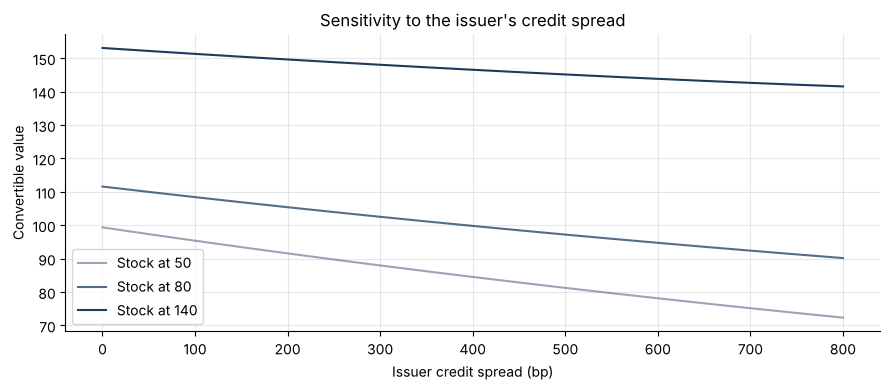

In [4]:
spreads = np.linspace(0.0, 0.08, 17)
plt.figure(figsize=(9, 4))
for s0, a in [(50, 0.45), (80, 0.75), (140, 1.0)]:
    plt.plot(spreads * 1e4, [price(cb, replace(m, spot=s0, credit_spread=s))["price"] for s in spreads],
             color=NAVY, alpha=a, label=f"Stock at {s0}")
plt.xlabel("Issuer credit spread (bp)"); plt.ylabel("Convertible value")
plt.title("Sensitivity to the issuer's credit spread"); plt.legend()
plt.tight_layout(); plt.savefig("images/credit_sensitivity.png", dpi=150); plt.show()

## 4. Call and put features

- **Issuer call** (from year 2 at 110): the issuer forces conversion once the bond is worth
  more than the call price, which caps the holder's upside: it lowers the value.
- **Holder put** (at 100 in year 3): the holder can hand the bond back, a floor on the
  price: it raises the value.

In [5]:
variants = {"Plain convertible": cb, "Callable from year 2 at 110": replace(cb, call_price=110, call_from=2.0),
            "Puttable at 100 in year 3": replace(cb, put_price=100, put_time=3.0),
            "Callable and puttable": replace(cb, call_price=110, call_from=2.0, put_price=100, put_time=3.0)}
feat = pd.DataFrame({name: price(c, m) for name, c in variants.items()}).T
feat["vs plain"] = feat["price"] - feat.loc["Plain convertible", "price"]
feat[["price", "vs plain", "delta", "gamma"]].round(3)

,price,vs plain,delta,gamma
Plain convertible,105.412,0.000,0.586,0.007
Callable from year 2 at 110,100.031,-5.381,0.509,0.010
Puttable at 100 in year 3,106.272,0.860,0.561,0.008
Callable and puttable,101.179,-4.233,0.480,0.010


## 5. From a market price to an implied credit spread

Convertible arbitrage desks turn the model around: given the market price of the
convertible, which credit spread is the market charging the issuer? If it is far from the
issuer's CDS spread (project 11), one of the two is mispriced.

In [6]:
for mkt_price in [100.0, 105.0, 110.0]:
    print(f"Market price {mkt_price:.1f}  ->  implied credit spread {implied_credit_spread(cb, m, mkt_price) * 1e4:.0f} bp")

Market price 100.0  ->  implied credit spread 393 bp


Market price 105.0  ->  implied credit spread 214 bp


Market price 110.0  ->  implied credit spread 50 bp


## Conclusions
- The Tsiveriotis-Fernandes tree prices the equity and credit parts consistently; it
  reduces exactly to the straight bond when the conversion right is removed (see tests).
- Today (stock at 80, conversion at 100) the convertible is worth 105.4: a 32% premium over
  parity and 22% over the bond floor, with a delta of 0.59.
- Calls cap the value and puts add a floor, and both change the delta the arbitrageur hedges.
- **Next steps:** a credit spread that widens when the stock falls (distressed zone),
  soft calls (e.g. callable if the stock exceeds 130% for 20 of 30 days), dividend protection.